Author: Aparajita Nath

Product: credit modelling: training the model using logistic regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import helpers as h

pd.set_option("display.max_columns", 30)

In [2]:
X_train, X_test, y_train, y_test = h.load_split()
categorical = h.categorical_columns(X_train)
print(X_train.shape, X_test.shape)

(700, 20) (300, 20)


## 3. Credit modelling

### 3.1 Tune the hyperparameters via GridSearchCV

Logistic regression: `C` is the inverse of the regularisation strength (small C = stronger shrinkage of the coefficients).

C: [0.01, 0.03, 0.1, 0.3, 1, 3, 10]

The preprocessing is inside the pipeline, so it is refitted on the training part of every fold. The score is ROC-AUC from 5-fold cross-validation repeated 3 times, on the training set only.

In [3]:
pipe = Pipeline([("preprocess", h.make_preprocess(categorical)),
                 ("model", LogisticRegression(max_iter=5000, random_state=h.SEED))])
grid = {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=h.SEED)
search = GridSearchCV(pipe, param_grid=grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)

print(f"Best cross-validated ROC-AUC: {search.best_score_:.3f}")
print("Best parameters:", search.best_params_)
cv_table = (pd.DataFrame(search.cv_results_)
            .loc[:, [c for c in search.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False).head(6))
cv_table.round(3)

Best cross-validated ROC-AUC: 0.792
Best parameters: {'model__C': 0.1}


,param_model__C,mean_test_score,std_test_score
2,0.10,0.792,0.039
3,0.30,0.791,0.040
1,0.03,0.788,0.038
4,1.00,0.787,0.040
5,3.00,0.783,0.040
6,10.00,0.780,0.041


### 3.2 Predict the PD on the held-out test set

In [4]:
model = search.best_estimator_
pd_test = model.predict_proba(X_test)[:, 1]

row = h.evaluate(y_test, pd_test, "Logistic regression")
pd.Series(row).drop("model").round(3).to_frame("Logistic regression")

,Logistic regression
roc_auc,0.768
auc_95ci_low,0.71
auc_95ci_high,0.824
gini,0.535
brier_score,0.169
mean_predicted_pd,0.308
observed_bad_rate,0.3


ROC-AUC and Gini (2 x AUC - 1) measure ranking. The Brier score measures the accuracy of the predicted probabilities. They are computed from the predicted probabilities, not from yes/no labels at a threshold.

### 3.3 Calibration of the PD

In [5]:
h.calibration_table(y_test, pd_test).round(3)

,cases,mean_predicted_pd,observed_bad_rate
score_bin,,,
Bin 1,60,0.069,0.050
Bin 2,60,0.156,0.150
Bin 3,60,0.269,0.317
Bin 4,60,0.401,0.350
Bin 5,60,0.643,0.633


### 3.4 Which inputs drive the model

The coefficients of the fitted regression, on the log-odds scale. Numeric inputs are standardised, so their coefficients are per one standard deviation. The other inputs are 0/1 indicators relative to the other categories of the same variable. The coefficients describe associations in this sample, not causes.

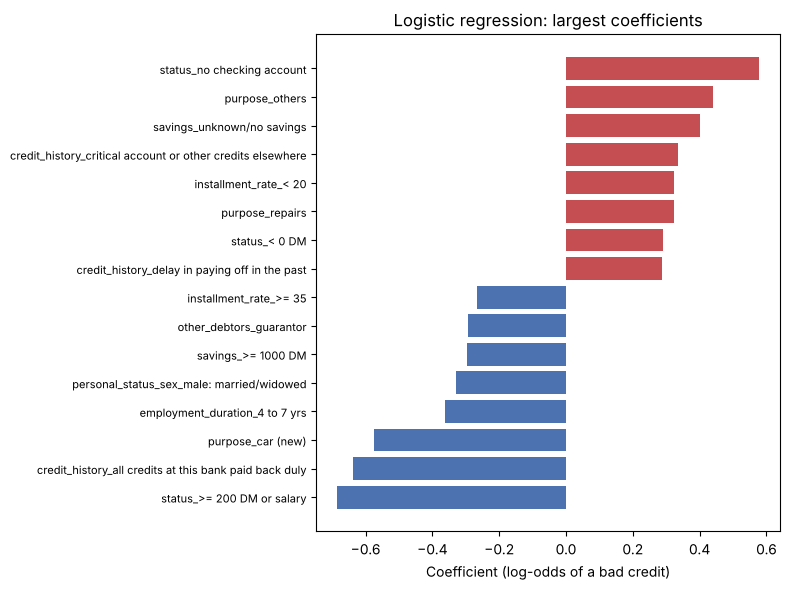

In [6]:
names = model.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(model.named_steps["model"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in top.values])
ax.set(xlabel="Coefficient (log-odds of a bad credit)", title="Logistic regression: largest coefficients")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(h.FIGURES / "lr_coefficients.png", dpi=160)
plt.show()

### 3.5 Save the predictions and the fitted model for the comparison (D) and monitoring (E)

In [7]:
out = pd.DataFrame({"pd_pred": pd_test, "bad_credit": y_test.to_numpy()}, index=y_test.index)
out.to_csv(h.OUTPUTS / "preds_LR.csv")
joblib.dump(model, h.MODELS / "LR.joblib")
print("Saved predictions and model")

Saved predictions and model
